# Notebook 04 — Ingeniería de Variables (Feature Engineering)

## Sensores Virtuales y Analizadores en Línea

El salto real de precisión en sensores virtuales nace de **traducir termodinámica e hidráulica de la torre en variables numéricas**:
1. `temp_gradient`: diferencial entre extracción de keroseno y tope de torre (selectividad del corte)
2. `tray_to_draw_diff`: gradiente interno plato 15 vs extracción
3. `specific_steam`: relación vapor de despojamiento / flujo de producto (eficiencia de *stripping*)
4. `yield_ratio`: fracción de keroseno extraída respecto a carga total
5. `condenser_approach`: salto térmico sobre la temperatura ambiente
6. **Inercia térmica:** `kerosene_draw_temp_lag1`, `lag2`, media móvil `ma9` (3 días) y `temp_gradient_lag1`
7. `post_crude_change`: indicador físico basado en `crude_api_gravity < 31.0`

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance

plt.style.use("seaborn-v0_8-whitegrid")
COLORS = ["#007297", "#8EC14B", "#E8820C", "#C0392B", "#0D202B"]
WORK_DIR = "/content" if os.path.isdir("/content") else "."

clean_path = os.path.join(WORK_DIR, "sensor_clean.csv")
if os.path.exists(clean_path):
    df = pd.read_csv(clean_path)
else:
    # Reconstrucción determinista si se ejecuta de forma aislada
    df = pd.read_csv("https://d29ikw7e1z6k4e.cloudfront.net/curso_sensor/curso_sensor_raw_data.csv").drop_duplicates().reset_index(drop=True)
    df.loc[(df["flash_point_lab_C"] <= 0) | (df["flash_point_lab_C"] >= 100), "flash_point_lab_C"] = np.nan
    n_tr, n_va = int(len(df) * 0.65), int(len(df) * 0.80)
    df["split"] = np.where(df.index < n_tr, "train", np.where(df.index < n_va, "val", "test"))
    pcols = [c for c in df.select_dtypes(include=[np.number]).columns if c != "flash_point_lab_C"]
    for c in pcols:
        p01, p99 = df.loc[:n_tr-1, c].quantile(0.01), df.loc[:n_tr-1, c].quantile(0.99)
        df[c] = df[c].clip(p01, p99).fillna(df.loc[:n_tr-1, c].median())

print(f"Dataset limpio cargado: {df.shape}")

Dataset limpio cargado: (1095, 18)


In [2]:
# Construcción de 10 variables físicas y temporales de proceso
df_feat = df.copy()

# Variables termodinámicas e hidráulicas instantáneas
df_feat["temp_gradient"]      = df_feat["kerosene_draw_temp_C"] - df_feat["column_top_temp_C"]
df_feat["tray_to_draw_diff"]  = df_feat["tray_15_temp_C"] - df_feat["kerosene_draw_temp_C"]
df_feat["specific_steam"]     = df_feat["stripping_steam_flow_kgh"] / (df_feat["kerosene_product_flow_m3h"] + 1e-6)
df_feat["yield_ratio"]        = df_feat["kerosene_product_flow_m3h"] / (df_feat["feed_flow_rate_m3h"] + 1e-6)
df_feat["condenser_approach"] = df_feat["condenser_outlet_temp_C"] - df_feat["ambient_temp_C"]

# Dinámica temporal (inercia de la torre: 1 turno = 8h, 9 turnos = 3 días)
df_feat["kerosene_draw_temp_lag1"] = df_feat["kerosene_draw_temp_C"].shift(1)
df_feat["kerosene_draw_temp_lag2"] = df_feat["kerosene_draw_temp_C"].shift(2)
df_feat["kerosene_draw_temp_ma9"]  = df_feat["kerosene_draw_temp_C"].rolling(window=9, min_periods=1).mean()
df_feat["temp_gradient_lag1"]      = df_feat["temp_gradient"].shift(1)

# Indicador basado en propiedad física del crudo (no en índice fijo)
df_feat["post_crude_change"] = (df_feat["crude_api_gravity"] < 31.0).astype(int)

# Filtrar únicamente filas con rezagos completos y etiqueta real de laboratorio
df_model_all = df_feat.dropna().reset_index(drop=True)
feature_cols_all = [c for c in df_model_all.columns if c not in ["date", "flash_point_lab_C", "split"]]

print(f"Variables predictoras totales generadas: {len(feature_cols_all)} (15 DCS/crudo + 10 derivadas)")
print(f"Filas válidas listas para modelado     : {len(df_model_all)} turnos con laboratorio verificado")

Variables predictoras totales generadas: 25 (15 DCS/crudo + 10 derivadas)
Filas válidas listas para modelado     : 1029 turnos con laboratorio verificado


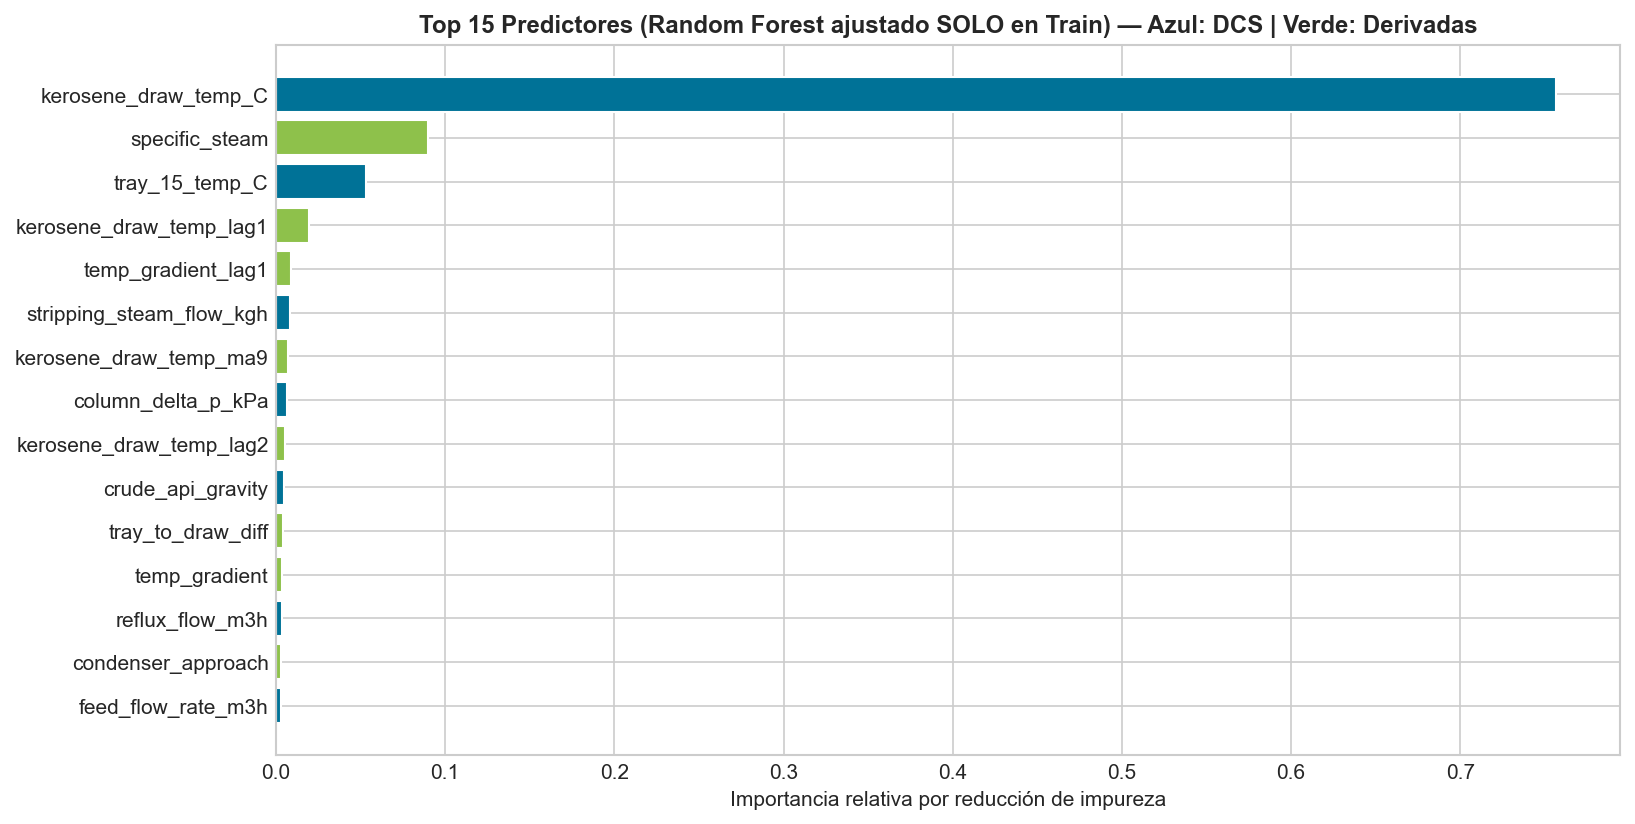

Top 8 predictores:
                 feature  importance                  tipo
    kerosene_draw_temp_C    0.756565          Original DCS
          specific_steam    0.089904 Derivada (Ingeniería)
          tray_15_temp_C    0.053079          Original DCS
 kerosene_draw_temp_lag1    0.019614 Derivada (Ingeniería)
      temp_gradient_lag1    0.008727 Derivada (Ingeniería)
stripping_steam_flow_kgh    0.008487          Original DCS
  kerosene_draw_temp_ma9    0.006896 Derivada (Ingeniería)
      column_delta_p_kPa    0.006639          Original DCS


In [3]:
# Evaluación de importancia de variables EXCLUSIVAMENTE en el conjunto Train (cero leakage)
tr_mask = df_model_all["split"] == "train"
X_tr_fe = df_model_all.loc[tr_mask, feature_cols_all]
y_tr_fe = df_model_all.loc[tr_mask, "flash_point_lab_C"]

rf_rank = RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1)
rf_rank.fit(X_tr_fe, y_tr_fe)

imp_df = pd.DataFrame({
    "feature": feature_cols_all,
    "importance": rf_rank.feature_importances_,
}).sort_values("importance", ascending=False).reset_index(drop=True)

derived_set = {
    "temp_gradient", "tray_to_draw_diff", "specific_steam", "yield_ratio",
    "condenser_approach", "kerosene_draw_temp_lag1", "kerosene_draw_temp_lag2",
    "kerosene_draw_temp_ma9", "temp_gradient_lag1", "post_crude_change"
}
imp_df["tipo"] = np.where(imp_df["feature"].isin(derived_set), "Derivada (Ingeniería)", "Original DCS")

fig, ax = plt.subplots(figsize=(11, 5.6), dpi=150)
top15 = imp_df.head(15).iloc[::-1]
bar_cols = [COLORS[1] if t == "Derivada (Ingeniería)" else COLORS[0] for t in top15["tipo"]]
ax.barh(top15["feature"], top15["importance"], color=bar_cols, edgecolor="white")
ax.set_title("Top 15 Predictores (Random Forest ajustado SOLO en Train) — Azul: DCS | Verde: Derivadas", fontsize=11.5, fontweight="bold")
ax.set_xlabel("Importancia relativa por reducción de impureza")
plt.tight_layout()
plt.show()

print("Top 8 predictores:")
print(imp_df.head(8).to_string(index=False))

In [4]:
# Guardamos las 25 variables ordenadas de forma reproducible para modelado y monitoreo PCA
out_ready = os.path.join(WORK_DIR, "sensor_model_ready.csv")
df_model_all.to_csv(out_ready, index=False)
print(f"Dataset listo para modelado guardado en: {os.path.abspath(out_ready)}")
print(f"Desglose por partición: {df_model_all['split'].value_counts().to_dict()}")

Dataset listo para modelado guardado en: /Users/santiagozapata/pungo-academy/course-production/sensores-virtuales/notebooks/sensor_model_ready.csv
Desglose por partición: {'train': 670, 'test': 206, 'val': 153}


### Checkpoint: Lo que debes ver

- **25 variables predictoras** (15 originales del proceso + 10 derivadas de ingeniería y rezagos térmicos)
- Varias variables derivadas (`specific_steam`, `temp_gradient`, `kerosene_draw_temp_lag1`, `temp_gradient_lag1`) dominando el ranking de importancia
- Archivo `sensor_model_ready.csv` guardado sin fuga temporal